# Phase 2. Data Science & Research
# Step 4. Exploratory Data Analysis

**Вопрос:** какие закономерности в игровых профилях и записанных рыночных оценках видны у центральных полузащитников?

Используются **2 886 CM на 26.09.2022** из Step 3. Это покрытая FIFA–Transfermarkt выборка, а не все футболисты мира. Оценка TM — не фактическая сумма сделки. Валюта в CSV не подтверждена отдельно: денежные оси обозначены как единицы источника.

| Гипотеза | Проверка и рабочий критерий |
| --- | --- |
| H1: сходные профили могут иметь разную стоимость | Для test-игрока выбирается ближайший train-игрок **без учёта цены**. Высокое сходство: cosine ≥0,90 и RMS различий исходных z-score ≤0,75. Существенная разница: max(value)/min(value) ≥2. |
| H2: игровые характеристики не полностью объясняют стоимость | Spearman на train; линейная и нелинейная регрессии на 18 игровых признаках, сравнение с медианой и контекстной моделью на 27 входах v1. Метрики на фиксированном test, bootstrap-интервалы. Остаток не интерпретируется автоматически как недооценённость. |
| H3: CM образуют группы с разными профилями | KMeans k=2…7 на train. Анализ исходных и очищенных от общего уровня профилей; silhouette, устойчивость к bootstrap и назначение кластеров test. Рабочие ориентиры: silhouette ≥0,20 и медианный ARI ≥0,60. |
| H4: среди дешёвых есть похожие на дорогих | Дорогие test-референсы ≥75-го перцентиля **train**-стоимости; кандидаты только из train, не дороже медианы train и не дороже половины референса. Те же пороги сходства; чувствительность и возраст/лига как дополнительные проверки. |

Пороговые значения фиксируются в коде до расчёта результатов этого notebook. Это **не пререгистрация**: данные уже изучались в предыдущих этапах. Статистика исследовательская; p-value не превращает наблюдение в причинный вывод.

Test из Step 3 теперь используется для EDA и сравнения моделей. После просмотра этих результатов он **больше не является нетронутым финальным тестом**. Для окончательных заявлений нужна новая независимая оценка или явно ограниченный протокол повторной валидации.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys
os.environ["LOKY_MAX_CPU_COUNT"] = "1"  # reproducible single-process execution; no Windows WMI core probe
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error, r2_score, silhouette_score, adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, OneHotEncoder, normalize
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from threadpoolctl import threadpool_limits
%matplotlib inline

_thread_limits = threadpool_limits(limits=1)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/feature_set_v1.json").exists())
FEATURE_DIR = ROOT / "data/processed/features"
OUT = ROOT / "data/processed/eda"
REPORT = ROOT / "reports/eda"
OUT.mkdir(parents=True, exist_ok=True)
REPORT.mkdir(parents=True, exist_ok=True)
SEED, BOOTSTRAPS = 42, 1000
SIM_THRESHOLD, RMS_THRESHOLD, PRICE_RATIO = .90, .75, 2.
K_VALUES = list(range(2, 8))
CLUSTER_REPEATS = 20
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30)
figures = []

def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def show(fig, name):
    for extension in ["png", "svg"]:
        fig.savefig(REPORT / f"{name}.{extension}", dpi=170, bbox_inches="tight", facecolor="white")
    figures.append(name)
    plt.show()
    plt.close(fig)

contract = json.loads((ROOT / "config/feature_set_v1.json").read_text(encoding="utf-8"))
manifest = json.loads((FEATURE_DIR / "feature_manifest.json").read_text(encoding="utf-8"))
params = json.loads((FEATURE_DIR / "transform_parameters.json").read_text(encoding="utf-8"))
for filename, metadata in manifest["outputs"].items():
    assert sha(FEATURE_DIR / filename) == metadata["sha256"], filename
data = pd.read_csv(FEATURE_DIR / "moneyball_features_2022-09-26.csv", dtype={"fifa_id": str, "tm_id": str, "league_id": str})
CORE = contract["similarity_features"]
VALUE_FEATURES = CORE + contract["valuation_additional_numeric_features"] + contract["valuation_additional_categorical_features"]
train = data.loc[data.split.eq("train")].reset_index(drop=True)
test = data.loc[data.split.eq("test")].reset_index(drop=True)
assert set(train.fifa_id).isdisjoint(test.fifa_id)
assert data.fifa_id.is_unique and data.tm_id.is_unique
assert data.as_of_date.eq(manifest["cutoff"]).all() and data.market_value_date.le(manifest["cutoff"]).all()
assert data.tm_market_value.gt(0).all()
assert hashlib.sha256("\n".join(sorted(train.fifa_id)).encode()).hexdigest() == params["train_ids_sha256"]
Z_train = (train[CORE].to_numpy(float) - np.array(params["similarity"]["mean"])) / np.array(params["similarity"]["scale"])
Z_test = (test[CORE].to_numpy(float) - np.array(params["similarity"]["mean"])) / np.array(params["similarity"]["scale"])
weights = np.array(params["similarity"]["weights"])
expected_weights = np.array([np.sqrt(1 / (len(contract["similarity_feature_groups"]) * len(fs)))
                            for feature in CORE for fs in contract["similarity_feature_groups"].values() if feature in fs])
assert params["similarity"]["features"] == CORE and np.allclose(weights,expected_weights)
W_train, W_test = Z_train * weights, Z_test * weights
assert np.allclose(Z_train.mean(axis=0), 0, atol=1e-12)
assert np.allclose(Z_train.std(axis=0), 1, atol=1e-12)
print("Train:", len(train), "; test:", len(test), "; all:", len(data), "; cutoff:", manifest["cutoff"])


Train: 2308 ; test: 578 ; all: 2886 ; cutoff: 2022-09-26


## 1. Распределения и границы исследования

Сравниваем исходную стоимость с логарифмом: несколько дорогих игроков могут определять среднее и ошибку в исходных единицах. Указываем медиану, перцентили и покрытие performance. График возраста и цены — ассоциация; он не устанавливает причинность.


,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
tm_market_value,2886.0,3373544.70,8192345.29,25000.00,175000.00,350000.00,800000.00,2500000.00,8000000.00,16000000.00,42450000.00,90000000.00
age_at_cutoff,2886.0,26.04,4.44,17.05,20.52,22.53,25.62,29.19,32.22,33.97,36.57,40.65
overall,2886.0,67.70,6.43,46.00,60.00,64.00,67.00,72.00,76.00,79.00,84.00,91.00


,all_players,known_minutes_21_22,reliable_goals_per90
0,2886,231,186


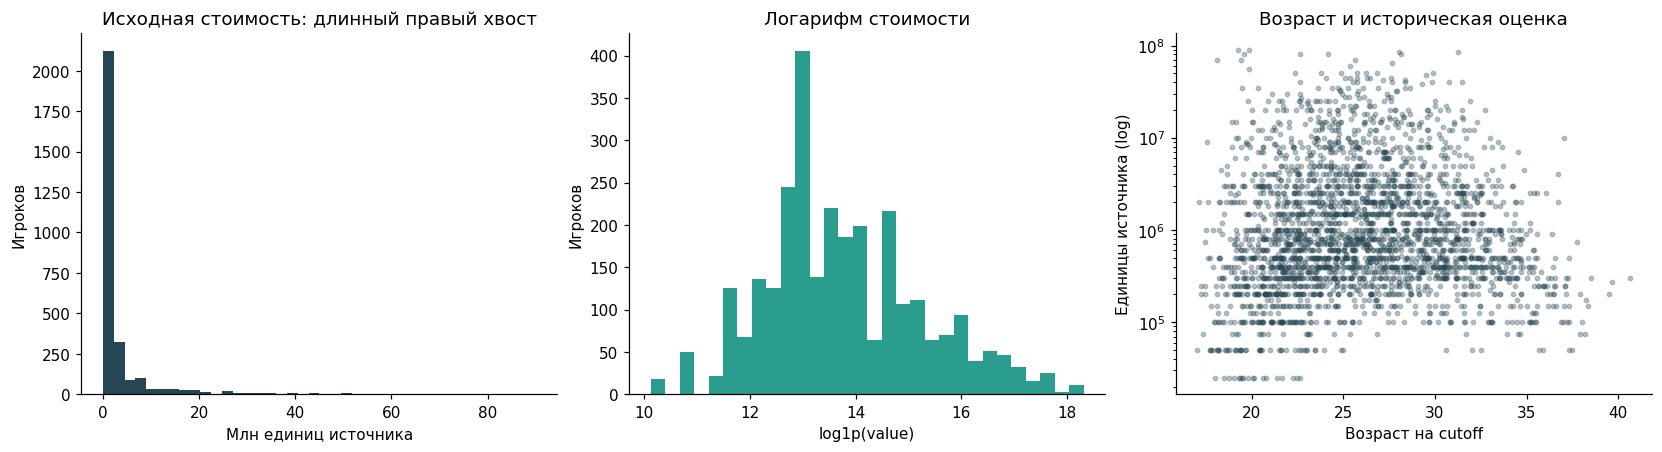

In [2]:
distribution = data[["tm_market_value", "age_at_cutoff", "overall"]].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]).T
display(distribution.round(2))
coverage = {"all_players": len(data), "known_minutes_21_22": int(data.minutes_21_22.notna().sum()),
            "reliable_goals_per90": int(data.goals_per90_450.notna().sum())}
display(pd.DataFrame([coverage]))
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
axes[0].hist(data.tm_market_value / 1e6, bins=40, color="#264653")
axes[0].set(title="Исходная стоимость: длинный правый хвост", xlabel="Млн единиц источника", ylabel="Игроков")
axes[1].hist(data.target_log1p_tm_value, bins=30, color="#2a9d8f")
axes[1].set(title="Логарифм стоимости", xlabel="log1p(value)", ylabel="Игроков")
axes[2].scatter(data.age_at_cutoff, data.tm_market_value, s=8, alpha=.3, color="#264653")
axes[2].set_yscale("log")
axes[2].set(title="Возраст и историческая оценка", xlabel="Возраст на cutoff", ylabel="Единицы источника (log)")
show(fig, "01_distributions")


## 2. H1: ближайшие профили без использования цены

Каждому test-игроку назначается ближайший по cosine train-игрок. Цены не используются для поиска и становятся доступны только после выбора пары. Группы ID не пересекаются, поэтому игрок не может найти самого себя.

Дополнительное ограничение RMS ≤0,75 на **не взвешенных z-score** защищает от ситуации, когда направления похожи, а уровни атрибутов существенно различаются. Отдельно показывается результат без этого ограничения. Подобранные пары могут делить одного соседа: bootstrap по референсам условен на фиксированной train-галерее и не описывает неопределённость всего рынка.


,test_anchors,high_similarity_pairs,pairs_ratio_ge_2,fraction_ratio_ge_2,conditional_bootstrap_95,cosine_only_pairs
0,578,221,132,0.597285,"[0.5339366515837104, 0.6606334841628959]",267


,reference_id,reference_name,reference_value,neighbor_id,neighbor_name,neighbor_value,cosine,rms_z,price_ratio,high_similarity,large_price_gap
556,269620,M. Portillo,25000.0,267702,K. Doumbia,2000000.0,0.912751,0.428239,80.000000,True,True
416,251990,Luquinha,700000.0,246174,H. Elliott,35000000.0,0.937560,0.496599,50.000000,True,True
63,199503,G. Xhaka,25000000.0,180283,Ki Sung Yueng,800000.0,0.920659,0.600594,31.250000,True,True
573,271501,A. Rodríguez,700000.0,246419,Y. Verschaeren,13000000.0,0.951658,0.366105,18.571429,True,True
203,224075,André Simões,600000.0,237520,M. Camara,11000000.0,0.930785,0.474011,18.333333,True,True
443,256098,R. Ledezma,850000.0,261993,Álex Cardero,50000.0,0.944014,0.337096,17.000000,True,True
115,207884,Willian Arão,6500000.0,179768,C. Kaboré,400000.0,0.923044,0.506604,16.250000,True,True
499,262242,S. Raebiger,750000.0,255455,Dani Albiar,50000.0,0.955212,0.281122,15.000000,True,True
5,173221,A. Candreva,2500000.0,208128,H. Çalhanoğlu,35000000.0,0.972968,0.641452,14.000000,True,True
134,210619,Jordi Quintillà,1500000.0,234943,F. Neuhaus,20000000.0,0.945251,0.655638,13.333333,True,True


,min_cosine,max_rms,eligible_pairs,ratio_ge_2
0,0.85,0.50,174,94
1,0.85,0.75,350,200
2,0.85,1.00,402,235
3,0.90,0.50,115,64
4,0.90,0.75,221,132
5,0.90,1.00,254,157
6,0.95,0.50,55,30
7,0.95,0.75,89,54
8,0.95,1.00,101,66


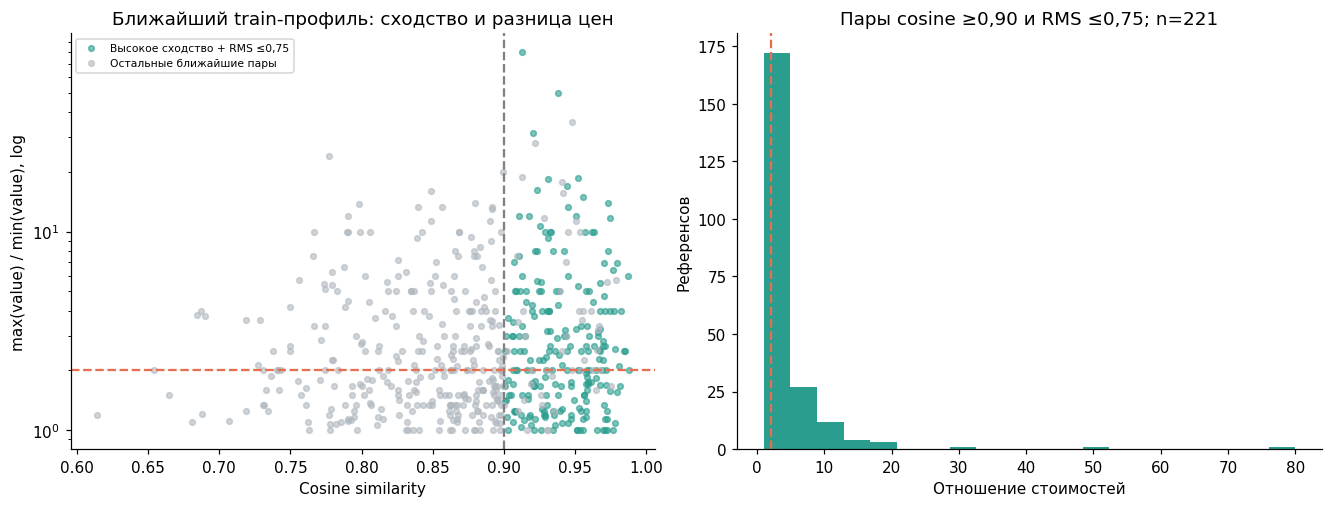

In [3]:
similarity = cosine_similarity(W_test, W_train)
rms = euclidean_distances(Z_test, Z_train) / np.sqrt(len(CORE))
nearest = similarity.argmax(axis=1)
rows = np.arange(len(test))
pairs = pd.DataFrame({
    "reference_id": test.fifa_id, "reference_name": test.short_name, "reference_value": test.tm_market_value,
    "neighbor_id": train.iloc[nearest].fifa_id.to_numpy(), "neighbor_name": train.iloc[nearest].short_name.to_numpy(),
    "neighbor_value": train.iloc[nearest].tm_market_value.to_numpy(), "cosine": similarity[rows, nearest], "rms_z": rms[rows, nearest],
})
pairs["price_ratio"] = np.maximum(pairs.reference_value, pairs.neighbor_value) / np.minimum(pairs.reference_value, pairs.neighbor_value)
pairs["high_similarity"] = pairs.cosine.ge(SIM_THRESHOLD) & pairs.rms_z.le(RMS_THRESHOLD)
pairs["large_price_gap"] = pairs.price_ratio.ge(PRICE_RATIO)
high_pairs = pairs.loc[pairs.high_similarity].copy()
assert pairs.reference_id.is_unique and not pairs.reference_id.eq(pairs.neighbor_id).any()

def conditional_bootstrap_fraction(values, repeats=BOOTSTRAPS):
    a = np.asarray(values, dtype=float)
    if not len(a):
        return [None, None]
    rng = np.random.default_rng(SEED)
    means = a[rng.integers(0, len(a), size=(repeats, len(a)))].mean(axis=1)
    return np.quantile(means, [.025, .975]).tolist()

h1_fraction = float(high_pairs.large_price_gap.mean()) if len(high_pairs) else None
h1_ci = conditional_bootstrap_fraction(high_pairs.large_price_gap)
h1_summary = {"test_anchors": len(pairs), "high_similarity_pairs": len(high_pairs),
              "pairs_ratio_ge_2": int(high_pairs.large_price_gap.sum()), "fraction_ratio_ge_2": h1_fraction,
              "conditional_bootstrap_95": h1_ci,
              "cosine_only_pairs": int(pairs.cosine.ge(SIM_THRESHOLD).sum())}
display(pd.DataFrame([h1_summary]))
display(high_pairs.sort_values("price_ratio", ascending=False).head(10))
sensitivity_h1 = pd.DataFrame([
    {"min_cosine": threshold, "max_rms": tolerance, "eligible_pairs": int((pairs.cosine.ge(threshold)&pairs.rms_z.le(tolerance)).sum()),
     "ratio_ge_2": int((pairs.cosine.ge(threshold)&pairs.rms_z.le(tolerance)&pairs.large_price_gap).sum())}
    for threshold in [.85,.90,.95] for tolerance in [.5,.75,1.0]])
display(sensitivity_h1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for mask,color,label in [(pairs.high_similarity,"#2a9d8f","Высокое сходство + RMS ≤0,75"),(~pairs.high_similarity,"#b0b8bf","Остальные ближайшие пары")]:
    axes[0].scatter(pairs.loc[mask,"cosine"], pairs.loc[mask,"price_ratio"], color=color, s=14, alpha=.6,label=label)
axes[0].legend(fontsize=7)
axes[0].axvline(SIM_THRESHOLD, color="grey", linestyle="--")
axes[0].axhline(PRICE_RATIO, color="#e76f51", linestyle="--")
axes[0].set_yscale("log")
axes[0].set(title="Ближайший train-профиль: сходство и разница цен", xlabel="Cosine similarity", ylabel="max(value) / min(value), log")
axes[1].hist(high_pairs.price_ratio, bins=20, color="#2a9d8f")
axes[1].axvline(PRICE_RATIO, color="#e76f51", linestyle="--")
axes[1].set(title=f"Пары cosine ≥0,90 и RMS ≤0,75; n={len(high_pairs)}", xlabel="Отношение стоимостей", ylabel="Референсов")
show(fig, "02_h1_similar_profiles_price_gap")


## 3. H2: ассоциации и предсказание стоимости

Spearman оценивает монотонную связь на **train**. Для 21 корреляции применяется Benjamini–Hochberg FDR: это поправка множества сравнений, а не контроль конфаундинга. Корреляции с overall/potential показываются для понимания игровых оценок, но эти поля не добавляются в основные 18/27 входов v1.

Один слабый коэффициент не означает отсутствие совместной предсказательной информации; высокий коэффициент не доказывает причинность или независимый эффект признака.


,feature,rho,p_value,q_bh
19,overall,0.80433,0.00000,0.00000
3,skill_ball_control,0.75770,0.00000,0.00000
0,attacking_short_passing,0.73977,0.00000,0.00000
20,potential,0.72462,0.00000,0.00000
7,movement_reactions,0.70349,0.00000,0.00000
4,skill_dribbling,0.69962,0.00000,0.00000
1,skill_long_passing,0.67916,0.00000,0.00000
8,mentality_composure,0.65221,0.00000,0.00000
2,mentality_vision,0.64468,0.00000,0.00000
17,power_long_shots,0.51596,0.00000,0.00000


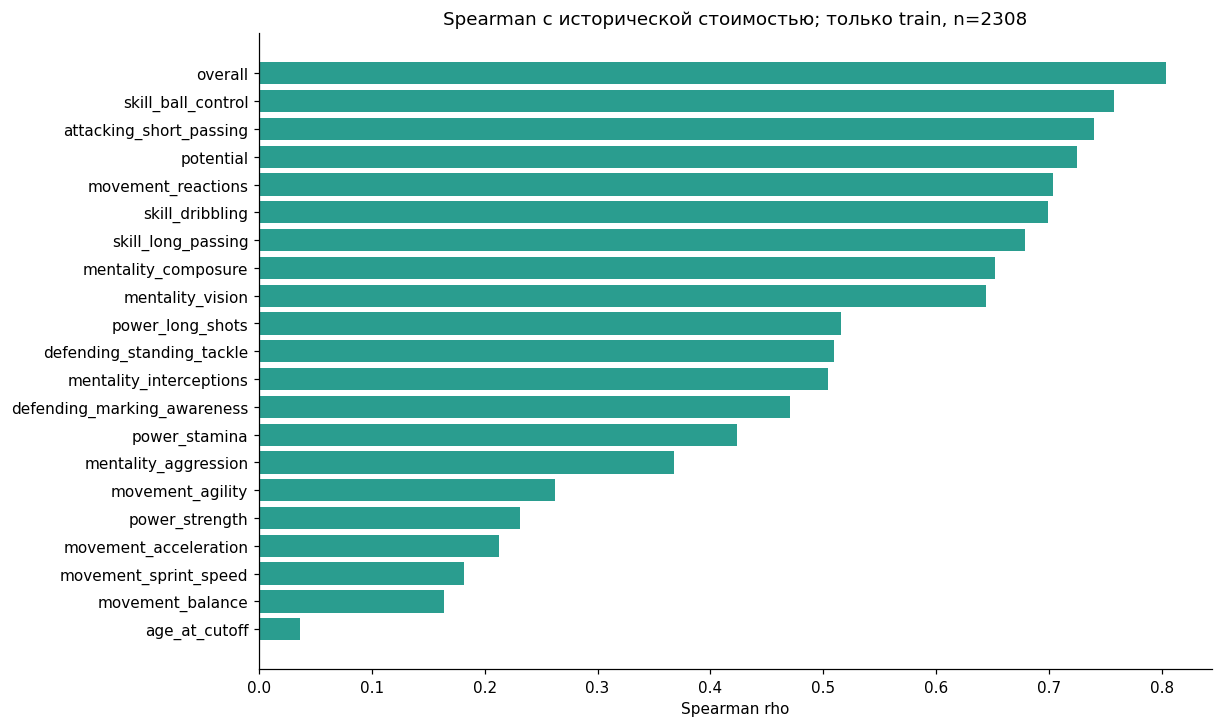

In [4]:
def bh_adjust(pvalues):
    p = np.asarray(pvalues, dtype=float)
    order = np.argsort(p)
    ranked = p[order] * len(p) / np.arange(1, len(p)+1)
    result = np.empty_like(p)
    result[order] = np.minimum(1, np.minimum.accumulate(ranked[::-1])[::-1])
    return result

correlation_rows = []
for feature in CORE + ["age_at_cutoff", "overall", "potential"]:
    statistic = spearmanr(train[feature], train.tm_market_value)
    correlation_rows.append({"feature": feature, "rho": float(statistic.statistic), "p_value": float(statistic.pvalue)})
correlations = pd.DataFrame(correlation_rows)
correlations["q_bh"] = bh_adjust(correlations.p_value)
display(correlations.sort_values("rho", ascending=False).round(5))
fig, ax = plt.subplots(figsize=(11, 6.5), layout="constrained")
ordered = correlations.sort_values("rho")
ax.barh(ordered.feature, ordered.rho, color=["#2a9d8f" if r>=0 else "#e76f51" for r in ordered.rho])
ax.axvline(0, color="grey", linewidth=.7)
ax.set(title=f"Spearman с исторической стоимостью; только train, n={len(train)}", xlabel="Spearman rho")
show(fig, "03_h2_correlations")


### Регрессия: CV для выбора, test для оценки

Цель — `log1p(tm_market_value)`. Медианное предсказание служит бейзлайном. Ridge проверяет линейную модель, HistGradientBoosting — нелинейную. Контекстная модель добавляет возраст, лигу и остальные поля фиксированного X_value v1, но не цену.

Гиперпараметры выбираются 5-fold CV **внутри train** по MAE лог-цены. Преобразования выполняются Pipeline внутри каждого fold; готовая матрица Step 3 не используется для подбора параметров, чтобы статистики всего train не попадали в CV-validation. Лучшая technical-модель определяется по CV, не по test.

Условные 95% bootstrap-интервалы на test отражают вариацию тестовых игроков при фиксированной модели. Они не включают неопределённость подбора/обучения модели. R² <1 сам по себе — тривиальное свойство несовершенного предсказания, а не доказательство существования конкретных скрытых факторов или рыночной ошибки.


,model,cv_log_mae,best_params
0,technical_ridge,0.646219,{'model__alpha': 10.0}
1,technical_nonlinear,0.620318,{'model__max_leaf_nodes': 7}
2,context_nonlinear,0.482505,{'model__max_leaf_nodes': 7}


,model,log_mae,r2,log_mae_low,log_mae_high,r2_low,r2_high,mae_source_units,median_fold_error_1plusvalue
0,median_baseline,1.2736,-0.0209,1.1945,1.3551,-0.0492,-0.0036,3.284256e+06,2.7500
1,technical_ridge,0.6634,0.7196,0.6194,0.7064,0.6769,0.7553,1.875612e+06,1.7509
2,technical_nonlinear,0.5956,0.7649,0.5579,0.6368,0.7285,0.7948,1.728472e+06,1.6450
3,context_nonlinear,0.4495,0.8572,0.4173,0.4812,0.8285,0.8789,1.127398e+06,1.4137


,selected_technical_by_cv,technical_test_r2,context_minus_technical_log_mae_improvement,paired_bootstrap_95
0,technical_nonlinear,0.764855,0.146125,"[0.1153647613204003, 0.17794657701024613]"


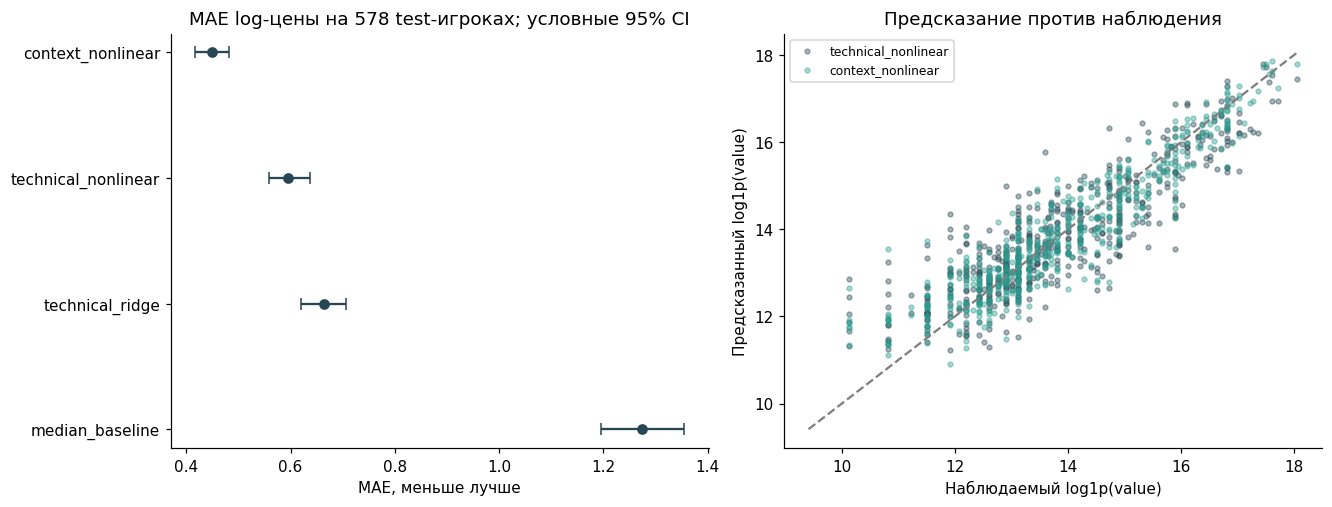

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
y_train = train.target_log1p_tm_value.to_numpy(float)
y_test = test.target_log1p_tm_value.to_numpy(float)
ridge = Pipeline([("scale", StandardScaler()), ("model", Ridge())])
technical_hgb = Pipeline([("model", HistGradientBoostingRegressor(max_iter=150, min_samples_leaf=30,
                         l2_regularization=1., early_stopping=False, random_state=SEED))])
numeric = CORE + contract["valuation_additional_numeric_features"]
categorical = contract["valuation_additional_categorical_features"]
context_preprocess = ColumnTransformer([
    ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical)], remainder="drop")
context_hgb = Pipeline([("preprocess", context_preprocess),
                        ("model", HistGradientBoostingRegressor(max_iter=150, min_samples_leaf=30,
                         l2_regularization=1., early_stopping=False, random_state=SEED))])
specifications = {
    "technical_ridge": (ridge, {"model__alpha": [.1,1.,10.,100.,1000.]}, CORE),
    "technical_nonlinear": (technical_hgb, {"model__max_leaf_nodes": [7,15]}, CORE),
    "context_nonlinear": (context_hgb, {"model__max_leaf_nodes": [7,15]}, VALUE_FEATURES),
}
fitted, predictions, cv_rows = {}, {}, []
baseline = DummyRegressor(strategy="median").fit(train[CORE], y_train)
predictions["median_baseline"] = baseline.predict(test[CORE])
for name, (estimator, grid, features) in specifications.items():
    search = GridSearchCV(estimator, grid, scoring="neg_mean_absolute_error", cv=cv, n_jobs=1, error_score="raise")
    search.fit(train[features], y_train)
    fitted[name] = search
    predictions[name] = search.predict(test[features])
    cv_rows.append({"model": name, "cv_log_mae": -float(search.best_score_), "best_params": str(search.best_params_)})
cv_results = pd.DataFrame(cv_rows)
best_technical = cv_results.loc[cv_results.model.str.startswith("technical")].sort_values("cv_log_mae").iloc[0].model
display(cv_results)
rng = np.random.default_rng(SEED)
bootstrap_indices = rng.integers(0, len(test), size=(BOOTSTRAPS, len(test)))
metric_rows = []
for name, pred in predictions.items():
    absolute = np.abs(y_test - pred)
    mae_samples = absolute[bootstrap_indices].mean(axis=1)
    observed_boot = y_test[bootstrap_indices]
    denominator = ((observed_boot-observed_boot.mean(axis=1, keepdims=True))**2).sum(axis=1)
    r2_samples = 1 - ((observed_boot-pred[bootstrap_indices])**2).sum(axis=1)/denominator
    metric_rows.append({"model": name, "log_mae": mean_absolute_error(y_test,pred), "r2": r2_score(y_test,pred),
                        "log_mae_low": float(np.quantile(mae_samples,.025)), "log_mae_high": float(np.quantile(mae_samples,.975)),
                        "r2_low": float(np.quantile(r2_samples,.025)), "r2_high": float(np.quantile(r2_samples,.975)),
                        "mae_source_units": mean_absolute_error(test.tm_market_value,np.expm1(np.maximum(pred,0))),
                        "median_fold_error_1plusvalue": float(np.median(np.exp(absolute)))})
regression = pd.DataFrame(metric_rows)
paired_improvement = np.abs(y_test-predictions[best_technical]) - np.abs(y_test-predictions["context_nonlinear"])
improvement_ci = np.quantile(paired_improvement[bootstrap_indices].mean(axis=1),[.025,.975]).tolist()
h2_summary = {"selected_technical_by_cv": str(best_technical), "technical_test_r2": float(r2_score(y_test,predictions[best_technical])),
              "context_minus_technical_log_mae_improvement": float(paired_improvement.mean()), "paired_bootstrap_95": improvement_ci}
display(regression.round(4))
display(pd.DataFrame([h2_summary]))
fig, axes = plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
axes[0].errorbar(regression.log_mae, np.arange(len(regression)),
                 xerr=np.array([regression.log_mae-regression.log_mae_low, regression.log_mae_high-regression.log_mae]), fmt="o",color="#264653",capsize=4)
axes[0].set_yticks(range(len(regression)),regression.model)
axes[0].set(title=f"MAE log-цены на {len(test)} test-игроках; условные 95% CI",xlabel="MAE, меньше лучше")
for name,color in [(best_technical,"#264653"),("context_nonlinear","#2a9d8f")]:
    axes[1].scatter(y_test,predictions[name],s=10,alpha=.4,label=name,color=color)
limits=[min(y_test.min(),min(p.min() for p in predictions.values())),max(y_test.max(),max(p.max() for p in predictions.values()))]
axes[1].plot(limits,limits,"--",color="grey")
axes[1].set(title="Предсказание против наблюдения",xlabel="Наблюдаемый log1p(value)",ylabel="Предсказанный log1p(value)")
axes[1].legend(fontsize=8)
show(fig,"04_h2_holdout_regression")


## 4. H3: кластеры профилей и проверка общего уровня

KMeans всегда создаёт заданное число групп; это не доказательство естественных дискретных типов футболистов. Сначала рассматриваем взвешенные z-score v1. Затем строим контроль **относительного профиля**: из z-score каждого игрока вычитаем его средний z-score по 18 атрибутам, применяем веса блоков и нормируем длину. Это удаляет общий сдвиг уровня атрибутов, но не гарантирует полную независимость от качества.

Для обоих представлений k=2…7 оценивается на одинаковой train-подвыборке (до 1 000 игроков). Основные стилевые кластеры выбираются по максимальному train silhouette относительного профиля. Возраст, цена, potential и test не участвуют в выборе k/fit.


,representation,k,train_silhouette,train_inertia
0,original_weighted,2,0.2461,1584.7585
1,original_weighted,3,0.1764,1365.3645
2,original_weighted,4,0.1735,1224.0551
3,original_weighted,5,0.1368,1143.5317
4,original_weighted,6,0.1349,1079.9640
5,original_weighted,7,0.1322,1029.0571
6,relative_style,2,0.1669,1899.1220
7,relative_style,3,0.1696,1609.3183
8,relative_style,4,0.1391,1494.1569
9,relative_style,5,0.1352,1412.1886


,train,test
0,841,201
1,766,189
2,701,188


,k,train_style_silhouette,test_style_silhouette,bootstrap_ari_median,bootstrap_ari_p05_p95,overall_range_of_cluster_means
0,3,0.169635,0.169011,0.85977,"[0.7785944983901077, 0.9676257250052223]",7.105988


,passing,ball_control,mobility,decisions,physical,defending,long_shots
cluster,,,,,,,
0,-0.591,-0.645,0.074,-0.518,0.074,0.047,-0.746
1,0.141,0.390,0.499,0.042,-0.518,-0.677,0.322
2,0.555,0.347,-0.633,0.575,0.477,0.683,0.543


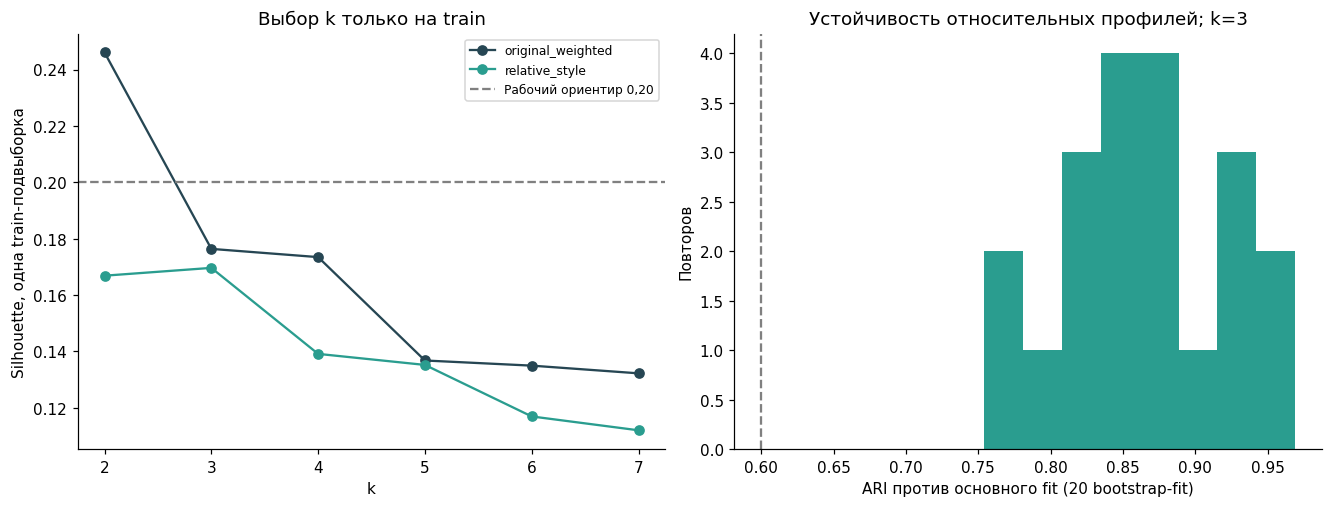

In [6]:
style_train = normalize((Z_train - Z_train.mean(axis=1,keepdims=True))*weights)
style_test = normalize((Z_test - Z_test.mean(axis=1,keepdims=True))*weights)
sample_ids = np.random.default_rng(SEED).choice(len(train),min(1000,len(train)),replace=False)
cluster_rows, cluster_models = [], {}
for representation, matrix in [("original_weighted",W_train),("relative_style",style_train)]:
    for k in K_VALUES:
        model = KMeans(n_clusters=k,n_init=10,random_state=SEED).fit(matrix)
        score = silhouette_score(matrix[sample_ids],model.labels_[sample_ids])
        cluster_rows.append({"representation":representation,"k":k,"train_silhouette":float(score),"train_inertia":float(model.inertia_)})
        cluster_models[(representation,k)] = model
cluster_selection = pd.DataFrame(cluster_rows)
best_k = int(cluster_selection.loc[cluster_selection.representation.eq("relative_style")].sort_values("train_silhouette",ascending=False).iloc[0].k)
cluster_model = cluster_models[("relative_style",best_k)]
train_labels = cluster_model.labels_
test_labels = cluster_model.predict(style_test)
stability = []
for repeat in range(CLUSTER_REPEATS):
    rng = np.random.default_rng(SEED+repeat)
    fit_ids = rng.integers(0,len(train),len(train))
    alternative = KMeans(n_clusters=best_k,n_init=10,random_state=SEED+repeat+1).fit(style_train[fit_ids])
    stability.append(float(adjusted_rand_score(train_labels,alternative.predict(style_train))))
test_silhouette = float(silhouette_score(style_test,test_labels)) if 1<len(np.unique(test_labels))<len(test) else None
style_cluster_data = train[["overall","tm_market_value"]].assign(cluster=train_labels)
group_blocks = contract["similarity_feature_groups"]
block_profiles = pd.DataFrame({block:Z_train[:,[CORE.index(f) for f in fs]].mean(axis=1) for block,fs in group_blocks.items()})
block_profiles["cluster"] = train_labels
block_centroids = block_profiles.groupby("cluster").mean()
relative_centroids = pd.DataFrame(style_train,columns=CORE).assign(cluster=train_labels).groupby("cluster").mean()
cluster_sizes = pd.DataFrame({"train":pd.Series(train_labels).value_counts(),"test":pd.Series(test_labels).value_counts()}).fillna(0).sort_index()
h3_summary = {"k":best_k,"train_style_silhouette":float(cluster_selection.loc[(cluster_selection.representation.eq("relative_style"))&cluster_selection.k.eq(best_k),"train_silhouette"].iloc[0]),
              "test_style_silhouette":test_silhouette,"bootstrap_ari_median":float(np.median(stability)),
              "bootstrap_ari_p05_p95":np.quantile(stability,[.05,.95]).tolist(),
              "overall_range_of_cluster_means":float(style_cluster_data.groupby("cluster").overall.mean().max()-style_cluster_data.groupby("cluster").overall.mean().min())}
display(cluster_selection.round(4)); display(cluster_sizes); display(pd.DataFrame([h3_summary])); display(block_centroids.round(3))
fig, axes=plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
for name,color in [("original_weighted","#264653"),("relative_style","#2a9d8f")]:
    part=cluster_selection.loc[cluster_selection.representation.eq(name)]
    axes[0].plot(part.k,part.train_silhouette,"o-",label=name,color=color)
axes[0].axhline(.2,color="grey",linestyle="--",label="Рабочий ориентир 0,20")
axes[0].set(title="Выбор k только на train",xlabel="k",ylabel="Silhouette, одна train-подвыборка"); axes[0].legend(fontsize=8)
axes[1].hist(stability,bins=8,color="#2a9d8f")
axes[1].axvline(.6,color="grey",linestyle="--")
axes[1].set(title=f"Устойчивость относительных профилей; k={best_k}",xlabel="ARI против основного fit (20 bootstrap-fit)",ylabel="Повторов")
show(fig,"05_h3_cluster_selection_stability")


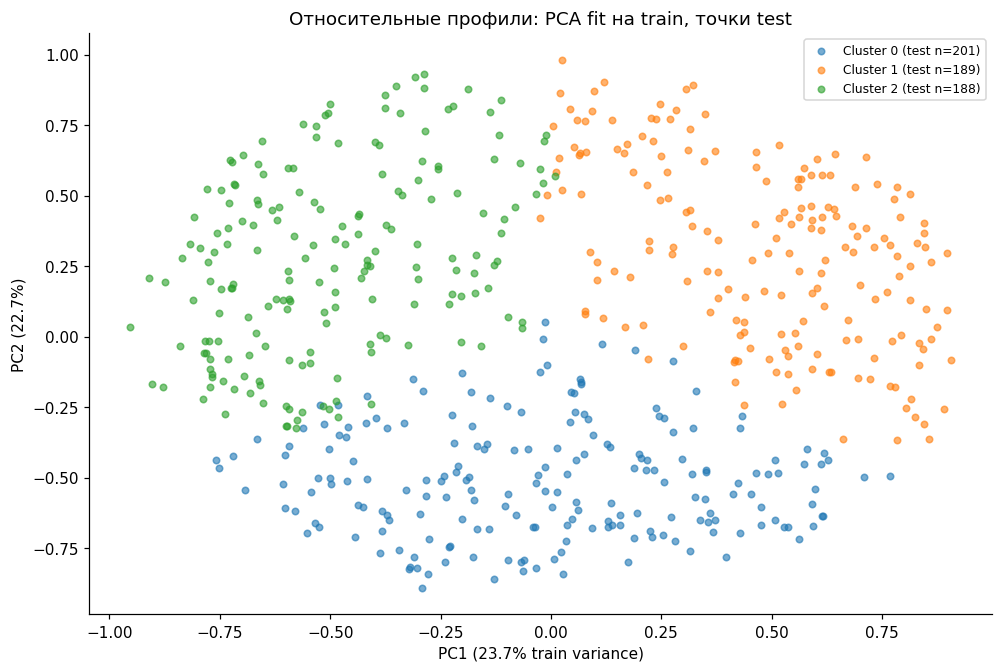

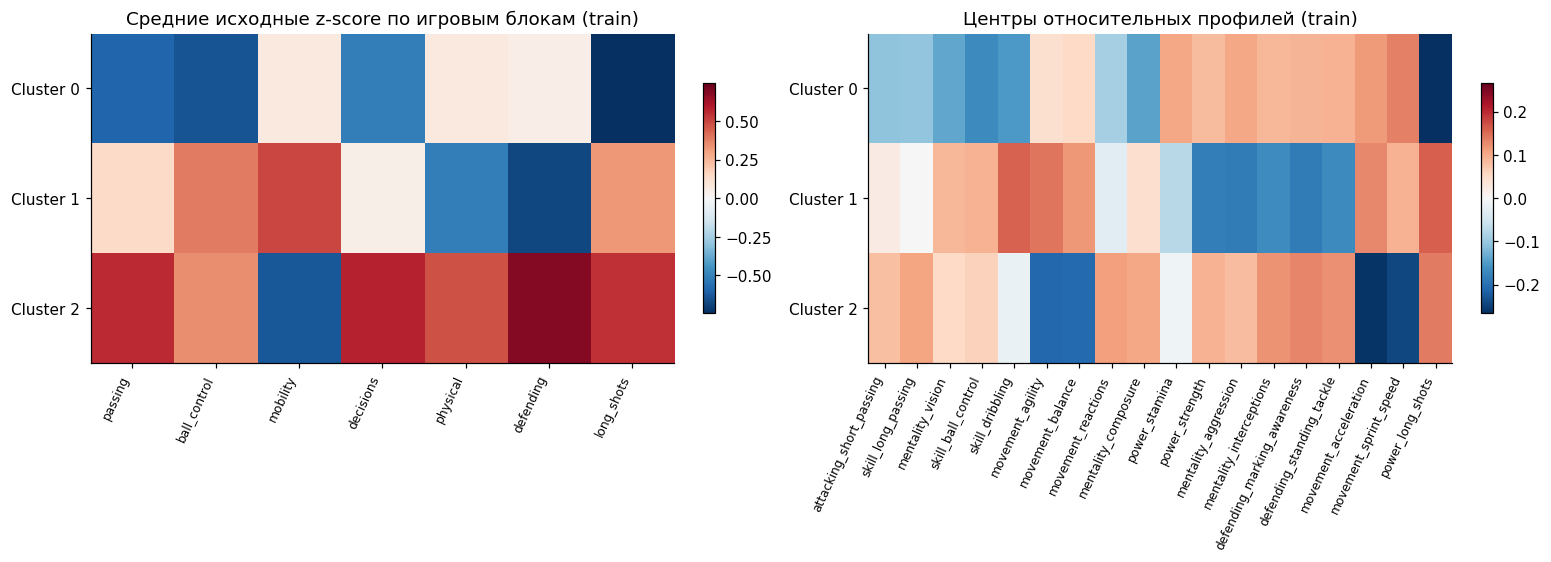

In [7]:
pca = PCA(n_components=2,random_state=SEED).fit(style_train)
projected_train, projected_test = pca.transform(style_train),pca.transform(style_test)
fig,ax=plt.subplots(figsize=(9,6),layout="constrained")
for cluster in range(best_k):
    mask=test_labels==cluster
    ax.scatter(projected_test[mask,0],projected_test[mask,1],s=18,alpha=.6,label=f"Cluster {cluster} (test n={mask.sum()})")
ax.set(title="Относительные профили: PCA fit на train, точки test",xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} train variance)",ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.legend(fontsize=8)
show(fig,"06_h3_pca_profiles")
fig,axes=plt.subplots(1,2,figsize=(14,5),layout="constrained")
for ax,frame,title in [(axes[0],block_centroids,"Средние исходные z-score по игровым блокам (train)"),
                       (axes[1],relative_centroids,"Центры относительных профилей (train)")]:
    limit=max(float(np.abs(frame.to_numpy()).max()),.01)
    im=ax.imshow(frame,vmin=-limit,vmax=limit,cmap="RdBu_r",aspect="auto")
    ax.set_xticks(range(frame.shape[1]),frame.columns,rotation=65,ha="right",fontsize=8)
    ax.set_yticks(range(best_k),[f"Cluster {i}" for i in range(best_k)])
    ax.set_title(title);fig.colorbar(im,ax=ax,shrink=.7)
show(fig,"07_h3_centroid_profiles")


## 5. H4: бюджетные кандидаты для дорогих референсов

Цена применяется как **фильтр допустимости**, а не как часть cosine или RMS. Референсы — только test; кандидаты — только train. Для каждого дорогого референса среди прошедших бюджет и сходство кандидатов выбирается самый похожий; сохраняются также до трёх кандидатов для ручного анализа.

Рабочие бюджеты определяются train-медианой, а дорогой сегмент — train-Q75. Это условные исследовательские границы, не реальный бюджет клуба. Возрастные и лиговые проверки показывают, сколько исходных кандидатов остаётся при дополнительных ограничениях; причинное объяснение разницы цен не устанавливается.


,budget_train_median,expensive_train_q75,expensive_test_references,references_with_candidate,references_with_age_gap_le3,references_with_same_league,coverage_fraction
0,800000.0,2425000.0,172,41,8,3,0.238372


,reference_id,reference_name,candidate_id,candidate_name,rank,reference_value,candidate_value,price_ratio,cosine,rms_z,reference_age,candidate_age,age_gap,same_known_league,reference_value_date,candidate_value_date
0,168651,I. Rakitić,235042,D. Liénard,1,7000000.0,700000.0,10.000,0.963,0.685,34.547,34.618,0.071,False,2022-06-02,2022-05-29
45,245275,T. Bašić,235042,D. Liénard,1,8000000.0,700000.0,11.429,0.950,0.403,25.835,34.618,8.783,False,2022-06-06,2022-05-29
50,247028,A. Král,197083,D. Caligiuri,1,5500000.0,800000.0,6.875,0.949,0.329,24.356,34.697,10.341,True,2022-09-20,2022-06-08
14,208268,B. Cristante,235042,D. Liénard,1,20000000.0,700000.0,28.571,0.949,0.582,27.568,34.618,7.050,False,2022-06-06,2022-05-29
43,243231,E. Mwepu,197083,D. Caligiuri,1,18000000.0,800000.0,22.500,0.945,0.536,24.734,34.697,9.963,False,2022-06-14,2022-06-08
27,224309,Joan Jordán,235042,D. Liénard,1,18000000.0,700000.0,25.714,0.942,0.600,28.225,34.618,6.393,False,2022-09-22,2022-05-29
40,240458,Ander Guevara,235042,D. Liénard,1,5000000.0,700000.0,7.143,0.940,0.353,25.222,34.618,9.396,False,2022-06-02,2022-05-29
21,212153,R. Gagliardini,235042,D. Liénard,1,8000000.0,700000.0,11.429,0.938,0.406,28.471,34.618,6.147,False,2022-06-06,2022-05-29
32,235167,V. Janelt,197083,D. Caligiuri,1,14000000.0,800000.0,17.500,0.938,0.379,24.381,34.697,10.316,False,2022-06-14,2022-06-08
25,219985,M. Vecino,235042,D. Liénard,1,3500000.0,700000.0,5.000,0.933,0.479,31.092,34.618,3.526,False,2022-06-06,2022-05-29


,budget_quantile,budget,min_cosine,covered_references,denominator
0,0.25,350000.0,0.85,19,172
1,0.25,350000.0,0.90,4,172
2,0.25,350000.0,0.95,0,172
3,0.50,800000.0,0.85,75,172
4,0.50,800000.0,0.90,41,172
5,0.50,800000.0,0.95,2,172
6,0.75,2425000.0,0.85,111,172
7,0.75,2425000.0,0.90,64,172
8,0.75,2425000.0,0.95,4,172


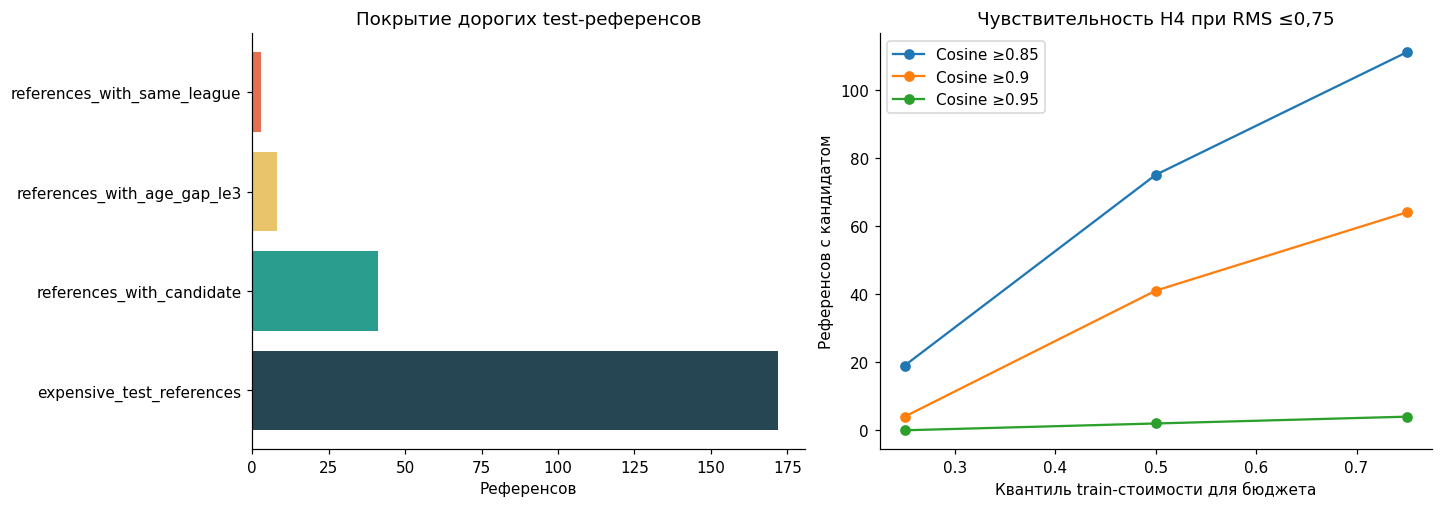

In [8]:
budget=float(train.tm_market_value.median())
expensive_threshold=float(train.tm_market_value.quantile(.75))
expensive=test.tm_market_value.ge(expensive_threshold).to_numpy()
budget_ok=(train.tm_market_value.to_numpy()[None,:]<=budget)&(train.tm_market_value.to_numpy()[None,:]<=test.tm_market_value.to_numpy()[:,None]/PRICE_RATIO)
style_ok=(similarity>=SIM_THRESHOLD)&(rms<=RMS_THRESHOLD)
admissible=budget_ok&style_ok&expensive[:,None]
candidate_rows=[]
for reference_index in np.flatnonzero(expensive):
    eligible=np.flatnonzero(admissible[reference_index])
    order=eligible[np.argsort(-similarity[reference_index,eligible],kind="stable")][:3]
    for rank,candidate_index in enumerate(order,start=1):
        ref,candidate=test.iloc[reference_index],train.iloc[candidate_index]
        candidate_rows.append({"reference_id":ref.fifa_id,"reference_name":ref.short_name,"candidate_id":candidate.fifa_id,
          "candidate_name":candidate.short_name,"rank":rank,"reference_value":float(ref.tm_market_value),"candidate_value":float(candidate.tm_market_value),
          "price_ratio":float(ref.tm_market_value/candidate.tm_market_value),"cosine":float(similarity[reference_index,candidate_index]),"rms_z":float(rms[reference_index,candidate_index]),
          "reference_age":float(ref.age_at_cutoff),"candidate_age":float(candidate.age_at_cutoff),"age_gap":abs(float(ref.age_at_cutoff-candidate.age_at_cutoff)),
          "same_known_league":bool(ref.league_id==candidate.league_id and ref.league_id!="UNKNOWN"),
          "reference_value_date":ref.market_value_date,"candidate_value_date":candidate.market_value_date})
candidates=pd.DataFrame(candidate_rows,columns=["reference_id","reference_name","candidate_id","candidate_name","rank","reference_value","candidate_value","price_ratio","cosine","rms_z","reference_age","candidate_age","age_gap","same_known_league","reference_value_date","candidate_value_date"])
best_candidates=candidates.loc[candidates["rank"].eq(1)].copy()
counts={"expensive_test_references":int(expensive.sum()),"references_with_candidate":int(best_candidates.reference_id.nunique()),
        "references_with_age_gap_le3":int((admissible & (np.abs(test.age_at_cutoff.to_numpy()[:,None]-train.age_at_cutoff.to_numpy()[None,:])<=3)).any(axis=1).sum()),
        "references_with_same_league":int((admissible & (test.league_id.to_numpy()[:,None]==train.league_id.to_numpy()[None,:]) & (train.league_id.to_numpy()[None,:]!="UNKNOWN")).any(axis=1).sum())}
h4_summary={"budget_train_median":budget,"expensive_train_q75":expensive_threshold,**counts,
            "coverage_fraction":len(best_candidates)/int(expensive.sum()) if expensive.sum() else None}
display(pd.DataFrame([h4_summary]));display(best_candidates.sort_values("cosine",ascending=False).head(12).round(3))
sensitivity_h4=[]
for budget_quantile in [.25,.50,.75]:
    cap=float(train.tm_market_value.quantile(budget_quantile))
    allowed=(train.tm_market_value.to_numpy()[None,:]<=cap)&(train.tm_market_value.to_numpy()[None,:]<=test.tm_market_value.to_numpy()[:,None]/PRICE_RATIO)
    for threshold in [.85,.90,.95]:
        mask=allowed&(similarity>=threshold)&(rms<=RMS_THRESHOLD)&expensive[:,None]
        sensitivity_h4.append({"budget_quantile":budget_quantile,"budget":cap,"min_cosine":threshold,"covered_references":int(mask.any(axis=1).sum()),"denominator":int(expensive.sum())})
sensitivity_h4=pd.DataFrame(sensitivity_h4)
display(sensitivity_h4)
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout="constrained")
axes[0].barh(list(counts),list(counts.values()),color=["#264653","#2a9d8f","#e9c46a","#e76f51"])
axes[0].set(title="Покрытие дорогих test-референсов",xlabel="Референсов")
for threshold in [.85,.90,.95]:
    part=sensitivity_h4.loc[sensitivity_h4.min_cosine.eq(threshold)]
    axes[1].plot(part.budget_quantile,part.covered_references,"o-",label=f"Cosine ≥{threshold}")
axes[1].set(title="Чувствительность H4 при RMS ≤0,75",xlabel="Квантиль train-стоимости для бюджета",ylabel="Референсов с кандидатом")
axes[1].legend()
show(fig,"08_h4_affordable_neighbors")


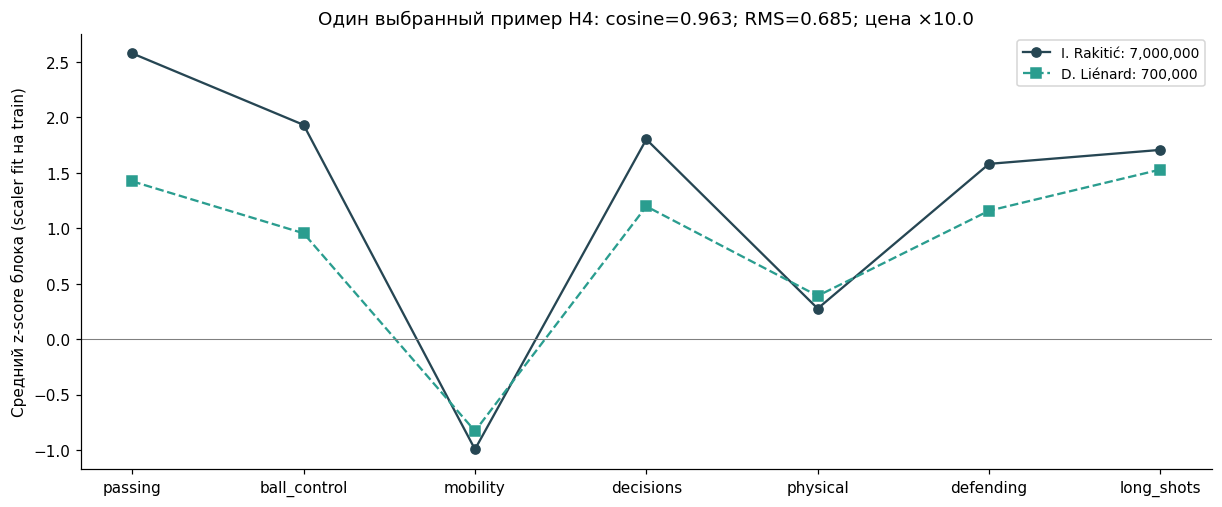

,reference_id,reference_name,candidate_id,candidate_name,rank,reference_value,candidate_value,price_ratio,cosine,rms_z,reference_age,candidate_age,age_gap,same_known_league,reference_value_date,candidate_value_date
0,168651,I. Rakitić,235042,D. Liénard,1,7000000.0,700000.0,10.0,0.963374,0.684917,34.546911,34.618096,0.071186,False,2022-06-02,2022-05-29


In [9]:
# Transparent case selection: highest cosine; tie-break lower RMS, then IDs.
if len(best_candidates):
    example=best_candidates.sort_values(["cosine","rms_z","reference_id","candidate_id"],ascending=[False,True,True,True]).iloc[0]
    ri=int(np.flatnonzero(test.fifa_id.eq(example.reference_id))[0]);ci=int(np.flatnonzero(train.fifa_id.eq(example.candidate_id))[0])
    ref_blocks=[float(Z_test[ri,[CORE.index(f) for f in fs]].mean()) for fs in group_blocks.values()]
    candidate_blocks=[float(Z_train[ci,[CORE.index(f) for f in fs]].mean()) for fs in group_blocks.values()]
    fig,ax=plt.subplots(figsize=(11,4.5),layout="constrained")
    ax.plot(list(group_blocks),ref_blocks,"o-",label=f"{example.reference_name}: {example.reference_value:,.0f}",color="#264653")
    ax.plot(list(group_blocks),candidate_blocks,"s--",label=f"{example.candidate_name}: {example.candidate_value:,.0f}",color="#2a9d8f")
    ax.axhline(0,color="grey",linewidth=.7)
    ax.set(title=f"Один выбранный пример H4: cosine={example.cosine:.3f}; RMS={example.rms_z:.3f}; цена ×{example.price_ratio:.1f}",ylabel="Средний z-score блока (scaler fit на train)")
    ax.legend(fontsize=9)
    show(fig,"09_h4_case_profile")
    display(pd.DataFrame([example]))
else:
    fig,ax=plt.subplots(figsize=(9,3),layout="constrained");ax.axis("off")
    ax.text(.5,.5,"При заданных критериях H4 кандидаты не найдены.\nПороги не ослабляются для получения положительного результата.",ha="center",va="center")
    show(fig,"09_h4_case_profile")


## 6. Интерпретация и ограничения

- H1 и H4 связаны между собой; они не являются двумя независимыми подтверждениями одного вывода. Пары выбраны алгоритмом, а не случайной выборкой пар.
- Даже при близких FIFA-атрибутах различия возраста, лиги, состояния контракта, реального качества и даты оценки могут объяснять цену. Контракты в архиве не восстановлены на cutoff.
- Дата оценки TM у разных игроков различается: это последняя доступная оценка до cutoff, а не обязательная переоценка всех в один день.
- Неполный матчинг и отбор положительных свежих оценок создают смещение выборки. В Step 1 средний overall связанных CM был выше, чем несвязанных. Выводы нельзя переносить на все дешёвые лиги и женский футбол.
- Performance ≥450 минут доступен лишь у 186 игроков и не участвует в основных тестах. Публикационное время сезонных итогов не подтверждено; будущие/текущие итоги не используются.
- Регрессия описывает записанную оценку TM, а не истинную стоимость, реальную сумму трансфера или будущий спортивный успех. Ценовой остаток не является доказанным undervaluation.
- Silhouette и устойчивость характеризуют выбранный алгоритм/геометрию. PCA — проекция для рисунка, а не доказательство кластеров. Имена Cluster 0…k−1 условны и не заменяют экспертное описание ролей.
- Bootstrap ARI рассчитан при фиксированном k: выбор числа кластеров не повторяется в каждом bootstrap. Сходство допускает различия отдельных атрибутов и не означает полную взаимозаменяемость игроков.
- Bootstrap-интервалы условны на этой когорте и обученных моделях; учёт всех этапов отбора/матчинга мог бы увеличить неопределённость.

Ниже выводы формируются из реально рассчитанных результатов. Итоговые статусы не являются решениями подтверждающего теста H0 и не доказывают причинность.


In [10]:
h3_operational_support=(h3_summary["train_style_silhouette"]>=.20 and h3_summary["bootstrap_ari_median"]>=.60)
conclusions=[
    {"hypothesis":"H1","status":"наблюдается в выборке" if h1_summary["pairs_ratio_ge_2"]>0 else "не обнаружено при заданных критериях",
     "evidence":f"{h1_summary['pairs_ratio_ge_2']} из {h1_summary['high_similarity_pairs']} ближайших пар с высоким сходством имеют разницу ≥2×; всего test-референсов {len(test)}.",
     "limit":"Условно на train-галерее и порогах; причины разницы цен не установлены."},
    {"hypothesis":"H2","status":"остаточная ошибка измерена; не причинный вывод",
     "evidence":f"Лучшая technical по CV: {best_technical}; test R²={h2_summary['technical_test_r2']:.3f}. Улучшение log-MAE от контекста={h2_summary['context_minus_technical_log_mae_improvement']:.3f}, 95% paired CI [{improvement_ci[0]:.3f}, {improvement_ci[1]:.3f}].",
     "limit":"Остаток включает ошибки модели/измерения; невозможно доказать универсальную недостаточность всех игровых признаков."},
    {"hypothesis":"H3","status":"рабочие критерии выполнены" if h3_operational_support else "рабочие критерии выполнены не полностью",
     "evidence":f"k={best_k}; train silhouette={h3_summary['train_style_silhouette']:.3f}; median bootstrap ARI={h3_summary['bootstrap_ari_median']:.3f}. Размах средних overall между группами даже после коррекции уровня: {h3_summary['overall_range_of_cluster_means']:.2f} пункта.",
     "limit":"Алгоритмические группы, а не доказанная естественная таксономия игровых ролей."},
    {"hypothesis":"H4","status":"кандидаты найдены" if len(best_candidates) else "кандидаты не найдены при заданных критериях",
     "evidence":f"{len(best_candidates)} из {int(expensive.sum())} дорогих test-референсов имеют более дешёвого train-кандидата; бюджет={budget:,.0f}, дорогой сегмент от {expensive_threshold:,.0f} единиц.",
     "limit":"Скаутинговые кандидаты; не доказательство недооценённости и не обещание успеха трансфера."},
]
display(pd.DataFrame(conclusions))
validation={
    "unique_ids":data.fifa_id.is_unique and data.tm_id.is_unique,
    "disjoint_train_test":set(train.fifa_id).isdisjoint(test.fifa_id),
    "historical_values":data.market_value_date.le(manifest["cutoff"]).all(),
    "no_economics_in_similarity":not set(CORE)&set(manifest["groups"]["economic"]),
    "neighbors_not_self":not pairs.reference_id.eq(pairs.neighbor_id).any(),
    "h1_anchors_test_neighbors_train":set(pairs.reference_id).issubset(set(test.fifa_id)) and set(pairs.neighbor_id).issubset(set(train.fifa_id)),
    "h4_prices_and_style":bool(candidates.empty or (candidates.candidate_value.le(budget).all() and candidates.price_ratio.ge(PRICE_RATIO).all() and candidates.cosine.ge(SIM_THRESHOLD).all() and candidates.rms_z.le(RMS_THRESHOLD).all())),
    "h4_dates_historical":bool(candidates.empty or (candidates.reference_value_date.le(manifest["cutoff"]).all() and candidates.candidate_value_date.le(manifest["cutoff"]).all())),
    "cluster_fit_train":len(cluster_model.labels_)==len(train),
    "pca_fit_train":pca.n_samples_==len(train),
    "finite_predictions":all(np.isfinite(v).all() for v in predictions.values()),
    "finite_pair_metrics":np.isfinite(pairs[["cosine","rms_z","price_ratio"]]).all().all(),
    "bh_adjustment_example":np.allclose(bh_adjust([.01,.04,.03]),[.03,.04,.04]),
    "context_input_allowlist":list(fitted["context_nonlinear"].best_estimator_.feature_names_in_)==VALUE_FEATURES,
}
assert all(validation.values()),{k:v for k,v in validation.items() if not v}
display(pd.DataFrame({"check":validation.keys(),"passed":validation.values()}))


,hypothesis,status,evidence,limit
0,H1,наблюдается в выборке,132 из 221 ближайших пар с высоким сходством и...,Условно на train-галерее и порогах; причины ра...
1,H2,остаточная ошибка измерена; не причинный вывод,Лучшая technical по CV: technical_nonlinear; t...,Остаток включает ошибки модели/измерения; нево...
2,H3,рабочие критерии выполнены не полностью,k=3; train silhouette=0.170; median bootstrap ...,"Алгоритмические группы, а не доказанная естест..."
3,H4,кандидаты найдены,41 из 172 дорогих test-референсов имеют более ...,Скаутинговые кандидаты; не доказательство недо...


,check,passed
0,unique_ids,True
1,disjoint_train_test,True
2,historical_values,True
3,no_economics_in_similarity,True
4,neighbors_not_self,True
5,h1_anchors_test_neighbors_train,True
6,h4_prices_and_style,True
7,h4_dates_historical,True
8,cluster_fit_train,True
9,pca_fit_train,True


In [11]:
for name,frame in [("h1_pairs.csv",pairs),("h1_sensitivity.csv",sensitivity_h1),("h4_candidates.csv",candidates),("h4_sensitivity.csv",sensitivity_h4)]:
    frame.to_csv(OUT/name,index=False)
prediction_table=test[["fifa_id","tm_market_value","target_log1p_tm_value"]].copy()
for name,pred in predictions.items():prediction_table[name]=pred
prediction_table.to_csv(OUT/"holdout_predictions.csv",index=False)
data_clusters=pd.concat([train[["fifa_id"]].assign(split="train",cluster=train_labels),test[["fifa_id"]].assign(split="test",cluster=test_labels)],ignore_index=True)
data_clusters.to_csv(OUT/"cluster_assignments.csv",index=False)
for name,frame in [("regression_metrics.csv",regression),("cv_model_selection.csv",cv_results),("train_correlations.csv",correlations),
                   ("cluster_selection.csv",cluster_selection),("cluster_sizes.csv",cluster_sizes.reset_index(names="cluster")),
                   ("cluster_block_profiles.csv",block_centroids.reset_index()),("hypothesis_conclusions.csv",pd.DataFrame(conclusions))]:
    frame.to_csv(REPORT/name,index=False)
summary={"cutoff":manifest["cutoff"],"n_players":len(data),"n_train":len(train),"n_test":len(test),
         "thresholds":{"cosine":SIM_THRESHOLD,"rms_z":RMS_THRESHOLD,"price_ratio":PRICE_RATIO},
         "H1":h1_summary,"H2":h2_summary,"H3":h3_summary,"H4":h4_summary,"conclusions":conclusions,
         "validation":{k:bool(v) for k,v in validation.items()},"figures":figures,
         "input_sha256":sha(FEATURE_DIR/"moneyball_features_2022-09-26.csv"),
         "holdout_status":"used_for_exploratory_analysis_not_untouched_final_test"}
(REPORT/"eda_summary.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False),encoding="utf-8")
lines=["# Moneyball 2.0: исследовательские результаты EDA","",f"Срез: {manifest['cutoff']}. Игроков: {len(data)}; train/test: {len(train)}/{len(test)}.",
       "", "Это исследовательские наблюдения на покрытой выборке FIFA–TM; они не доказывают причинность, рыночную ошибку или успех трансфера.",""]
for result in conclusions:
    lines.extend([f"## {result['hypothesis']}: {result['status']}","",result["evidence"],"",result["limit"],""])
lines.extend(["## Дополнительные результаты","",f"Доля H1-пар с разницей ≥2×: {h1_fraction:.1%}; условный bootstrap 95% CI [{h1_ci[0]:.1%}, {h1_ci[1]:.1%}]." if h1_fraction is not None else "При заданных критериях H1 близкие пары отсутствуют.",
              "",f"H3 silhouette test: {test_silhouette:.3f}." if test_silhouette is not None else "H3 silhouette test не определён.",
              "",f"H4: кандидаты с разницей возраста ≤3 года есть у {counts['references_with_age_gap_le3']} референсов; кандидаты той же известной лиги — у {counts['references_with_same_league']}.",
              "", "## Использование в презентации","", "Графики PNG и SVG: `reports/eda/`. Таблицы метрик и агрегированных выводов лежат рядом. Пары игроков и предсказания сохранены локально в `data/processed/eda/`.",
              "", "Test уже использован в EDA; не представлять его как новый независимый финальный тест на следующем этапе."])
(ROOT/"docs/eda_findings.md").write_text("\n".join(lines)+"\n",encoding="utf-8")
display(Markdown(f"**EDA завершён:** {len(figures)} фигур (PNG + SVG), четыре гипотезы с рассчитанными выводами, метрики CV/test, интервалы и таблицы кандидатов. "
                 "Сводка для презентации: `docs/eda_findings.md`; рисунки: `reports/eda/`."))


**EDA завершён:** 9 фигур (PNG + SVG), четыре гипотезы с рассчитанными выводами, метрики CV/test, интервалы и таблицы кандидатов. Сводка для презентации: `docs/eda_findings.md`; рисунки: `reports/eda/`.